# 06 · Prétraitement des images avant le réseau

**Objectif** : brancher un réseau derrière (POD puis réseau) pour trouver la séparation eau / berge. Avant ça, chaque photo passe par deux étapes :

1. `decouper(img, recaler=...)` : on garde une **bande serrée** autour de la frontière eau / berge, y ∈ [600, 1000]. C'est la bande « où se trouve la frontière » définie dans `annotation_tools.py` (plus serrée que la bande [500, 1200] des notebooks 01 à 04). On garde toute la largeur, moins une marge de 40 px de chaque côté. Option : décaler la bande de `decalage_x` / `decalage_y` (mouvement de la caméra, voir le catalogue) pour que chaque pixel corresponde au même endroit de la scène.
2. `normaliser(img)` : noir et blanc, puis on enlève à chaque pixel la moyenne de l'image et on divise par son écart type. Le résultat a une moyenne 0 et un écart type 1.

On les applique ensuite à la suite : `normaliser(decouper(img))`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMAGES = ROOT / "data" / "images"
CATALOGUE = ROOT / "data_treatment" / "catalogue_images.csv"

W0, H0 = 1919, 1753          # taille des images (pleine résolution)
Y0, Y1 = 500, 1100           # bande serrée autour de la frontière (annotation_tools.py)
MARGE = 40                   # marge à gauche et à droite (> |decalage_x| max, 37 px)

cat = pd.read_csv(CATALOGUE).set_index("fichier")

## 1. Les deux fonctions

In [2]:
def decouper(img, decalage_x=0.0, decalage_y=0.0):
    """Découpe la bande serrée y ∈ [Y0, Y1], x ∈ [MARGE, W0 - MARGE] (coordonnées pleine résolution).

    img : image PIL (pleine résolution 1919 x 1753, ou décodée plus petite : les coordonnées sont mises à l'échelle).
    decalage_x, decalage_y : déplacement de la scène par rapport à l'image de référence (colonnes du catalogue).
        La bande est décalée d'autant : un point en y sur la référence est en y + decalage_y sur la photo.
    Renvoie une image PIL.
    """
    s = img.size[0] / W0
    gauche, haut = round((MARGE + decalage_x) * s), round((Y0 + decalage_y) * s)
    largeur, hauteur = round((W0 - 2 * MARGE) * s), round((Y1 - Y0) * s)   # taille fixe, quel que soit le décalage
    return img.crop((gauche, haut, gauche + largeur, haut + hauteur))


def normaliser(img):
    """Noir et blanc, puis (img - moyenne) / écart type, calculés sur toute l'image.

    img : image PIL ou tableau numpy (H, W, 3) ou (H, W).
    Renvoie un tableau float32 (H, W) de moyenne 0 et d'écart type 1.
    """
    if isinstance(img, Image.Image):
        x = np.asarray(img.convert("L"), dtype=np.float64)
    else:
        x = np.asarray(img, dtype=np.float64)
        if x.ndim == 3:
            x = x[..., :3] @ np.array([0.299, 0.587, 0.114])   # luminance, même formule que PIL
    ecart_type = x.std()
    return ((x - x.mean()) / (ecart_type if ecart_type > 0 else 1.0)).astype(np.float32)


def preparer(nom, recaler=True):
    """Les deux étapes à la suite pour une photo du dossier data/images."""
    img = Image.open(IMAGES / nom)
    dx, dy = (cat.at[nom, "decalage_x"], cat.at[nom, "decalage_y"]) if recaler else (0.0, 0.0)
    if not (np.isfinite(dx) and np.isfinite(dy)):      # alignement inconnu : pas de recalage
        dx = dy = 0.0
    return normaliser(decouper(img, dx, dy))

## 2. La bande contient-elle bien la frontière ?

Sur toutes les photos annotées, la frontière (niveau annoté) doit tomber dans la bande découpée. Avec le recalage, la frontière est en y = `niveau_px - decalage_y - Y0` dans la bande.

In [3]:
annot = pd.concat([pd.read_csv(f) for f in sorted((ROOT / "data_treatment" / "annotations").glob("niveau_*.csv"))])
annot = annot.dropna(subset=["niveau_px"]).drop_duplicates("fichier").set_index("fichier")
annot = annot.join(cat[["decalage_x", "decalage_y"]], how="inner")
y_bande = annot["niveau_px"] - annot["decalage_y"].fillna(0) - Y0
print(f"{len(annot)} photos annotées")
print(f"frontière dans la bande : y de {y_bande.min():.0f} à {y_bande.max():.0f} px (hauteur de la bande : {Y1 - Y0} px)")
print(f"photos dont la frontière sort de la bande : {((y_bande < 0) | (y_bande > Y1 - Y0)).sum()}")

4376 photos annotées
frontière dans la bande : y de 66 à 398 px (hauteur de la bande : 600 px)
photos dont la frontière sort de la bande : 0


## 3. Application à la suite sur quelques photos

Pour chaque photo : l'originale avec la bande en rouge, la bande découpée, puis la bande normalisée (noir et blanc, moyenne 0, écart type 1). Ligne jaune : niveau annoté.

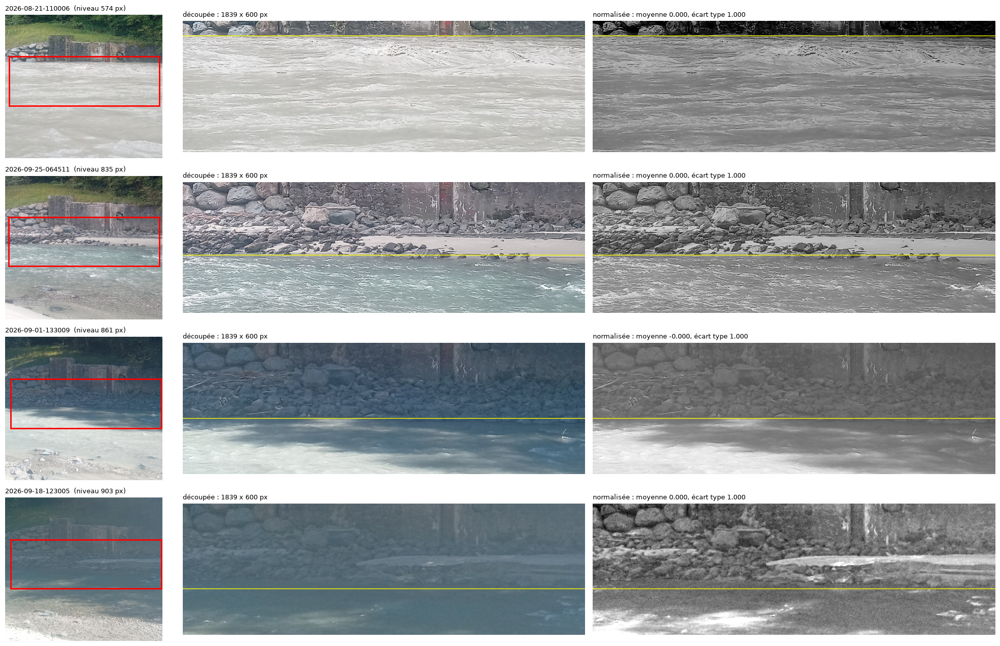

In [4]:
exemples = annot.sort_values("niveau_px").iloc[np.linspace(0, len(annot) - 1, 4).astype(int)].index

fig, axes = plt.subplots(len(exemples), 3, figsize=(20, 3.2 * len(exemples)),
                         gridspec_kw={"width_ratios": [1, 2.2, 2.2]})
for ligne, nom in zip(axes, exemples):
    img = Image.open(IMAGES / nom)
    dx, dy = cat.at[nom, "decalage_x"], cat.at[nom, "decalage_y"]
    bande = decouper(img, dx, dy)
    x = normaliser(bande)
    y_front = annot.at[nom, "niveau_px"] - (Y0 + dy)

    ligne[0].imshow(img)
    ligne[0].add_patch(plt.Rectangle((MARGE + dx, Y0 + dy), W0 - 2 * MARGE, Y1 - Y0, fill=False, ec="red", lw=2))
    ligne[0].set_title(f"{nom[:-4]}  (niveau {annot.at[nom, 'niveau_px']:.0f} px)", fontsize=9, loc="left")
    ligne[1].imshow(bande)
    ligne[1].axhline(y_front, color="yellow", lw=1)
    ligne[1].set_title(f"découpée : {bande.size[0]} x {bande.size[1]} px", fontsize=9, loc="left")
    ligne[2].imshow(x, cmap="gray", vmin=-3, vmax=3)
    ligne[2].axhline(y_front, color="yellow", lw=1)
    ligne[2].set_title(f"normalisée : moyenne {x.mean():.3f}, écart type {x.std():.3f}", fontsize=9, loc="left")
    for ax in ligne:
        ax.axis("off")
plt.tight_layout()

Vérification : sur un échantillon de photos annotées, `preparer` donne des tableaux de même taille, de moyenne 0 et d'écart type 1.

In [5]:
echantillon = annot.sample(50, random_state=0).index
X = np.stack([preparer(f) for f in echantillon])
print("forme :", X.shape, "(photos, hauteur, largeur)")
print("moyennes     : min", X.mean(axis=(1, 2)).min().round(4), " max", X.mean(axis=(1, 2)).max().round(4))
print("écarts types : min", X.std(axis=(1, 2)).min().round(4), " max", X.std(axis=(1, 2)).max().round(4))

forme : (50, 600, 1839) (photos, hauteur, largeur)
moyennes     : min -0.0  max 0.0
écarts types : min 1.0  max 1.0


## 4. POD des images prétraitées

On applique `decouper` (avec recalage) puis `normaliser` à **toutes les photos exploitables du train** (catalogue `exploitable == "oui"`, `split == "train"` dans `split_train_test.csv`, produit par `data_treatment/split_train_test.py` d'Aymen : par défaut 4 semaines de train puis 1 semaine de test), annotées ou non : la POD n'a pas besoin des niveaux. Les photos test ne servent pas à construire la base, on les projette seulement dessus, pour pouvoir évaluer le réseau honnêtement ensuite.

Pour que le calcul tienne en mémoire, chaque bande est réduite à 1/4 : 150 × 460 pixels, soit p = 69 000 valeurs par photo.

**POD** : avec $X$ la matrice (photos × pixels) et $\bar{x}$ l'image moyenne, on décompose $X - \bar{x} = U\,\Sigma\,V^T$. Les lignes de $V^T$ sont les **modes** (des images), $a = U\Sigma$ les **coefficients** de chaque photo sur ces modes. Comme il y a beaucoup moins de photos que de pixels, on passe par la matrice de corrélation entre photos $(X - \bar{x})(X - \bar{x})^T$ (méthode des snapshots), de taille n × n seulement.

In [6]:
from concurrent.futures import ThreadPoolExecutor

ECHELLE = 4
TAILLE = ((W0 - 2 * MARGE) // ECHELLE, (Y1 - Y0) // ECHELLE)     # (largeur, hauteur) de la bande réduite


def charger(nom):
    """decouper (recalée) puis normaliser, sur la photo décodée à 1/ECHELLE. Renvoie un vecteur float32."""
    img = Image.open(IMAGES / nom)
    img.draft("L", (img.size[0] // ECHELLE, img.size[1] // ECHELLE))   # décodage JPEG directement à petite taille
    bande = decouper(img.convert("L"), cat.at[nom, "decalage_x"], cat.at[nom, "decalage_y"]).resize(TAILLE)
    return normaliser(bande).ravel()


split = pd.read_csv(ROOT / "data_treatment" / "split_train_test.csv").set_index("fichier")["split"]
utiles = cat.index[(cat["exploitable"] == "oui") & cat["decalage_y"].notna()]
fichiers = {s: sorted(f for f in utiles if split.get(f) == s) for s in ("train", "test")}

with ThreadPoolExecutor(8) as ex:
    X = {s: np.stack(list(ex.map(charger, f))) for s, f in fichiers.items()}
h, w = TAILLE[1], TAILLE[0]
print({s: x.shape for s, x in X.items()}, f"-> bandes de {h} x {w} px")

{'train': (3494, 68850), 'test': (883, 68850)} -> bandes de 150 x 459 px


In [7]:
K_MAX = len(X["train"]) - 1                 # tous les modes (le dernier est nul : on a retiré la moyenne)

xbar = X["train"].mean(axis=0)
A = X["train"] - xbar                         # fluctuations autour de l'image moyenne
C = (A.astype(np.float64) @ A.T.astype(np.float64))         # n x n : corrélations entre photos
valeurs, vecteurs = np.linalg.eigh(C)
ordre = np.argsort(valeurs)[::-1]
valeurs, vecteurs = np.clip(valeurs[ordre], 0, None), vecteurs[:, ordre]

energie = valeurs / valeurs.sum()             # part de l'énergie (variance) portée par chaque mode
sigma = np.sqrt(valeurs[:K_MAX])
modes = ((A.T @ vecteurs[:, :K_MAX].astype(np.float32)) / sigma.astype(np.float32)).T   # (K_MAX, p), orthonormés
coefs = {"train": A @ modes.T, "test": (X["test"] - xbar) @ modes.T}                     # (n, K_MAX)

for k in (1, 5, 10, 20, 50, 100, 200, 300, 500, 1000, 2000, K_MAX):
    print(f"{k:5d} modes : {100 * energie[:k].sum():5.1f} % de l'énergie")

    1 modes :  23.4 % de l'énergie
    5 modes :  51.2 % de l'énergie
   10 modes :  62.0 % de l'énergie
   20 modes :  70.4 % de l'énergie
   50 modes :  78.0 % de l'énergie
  100 modes :  82.0 % de l'énergie
  200 modes :  85.3 % de l'énergie
  300 modes :  87.1 % de l'énergie
  500 modes :  89.6 % de l'énergie
 1000 modes :  93.4 % de l'énergie
 2000 modes :  97.6 % de l'énergie
 3493 modes : 100.0 % de l'énergie


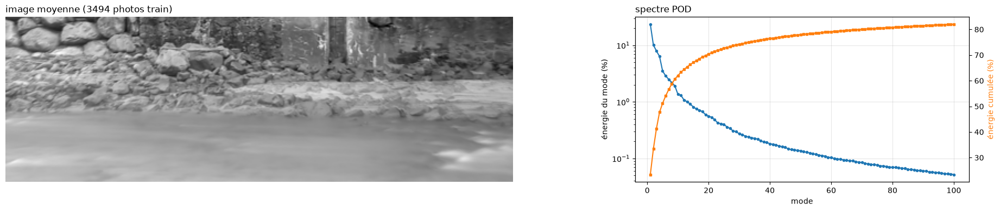

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(20, 4), gridspec_kw={"width_ratios": [2, 1]})
ax[0].imshow(xbar.reshape(h, w), cmap="gray")
ax[0].set_title(f"image moyenne ({len(X['train'])} photos train)", loc="left"); ax[0].axis("off")
K = np.arange(1, 101)
ax[1].semilogy(K, 100 * energie[:100], "o-", ms=3, label="énergie du mode (%)")
ax2 = ax[1].twinx()
ax2.plot(K, 100 * np.cumsum(energie[:100]), "s-", ms=3, color="tab:orange", label="énergie cumulée (%)")
ax[1].set_xlabel("mode"); ax[1].set_ylabel("énergie du mode (%)"); ax2.set_ylabel("énergie cumulée (%)", color="tab:orange")
ax[1].grid(alpha=.3); ax[1].set_title("spectre POD", loc="left")
plt.tight_layout()

### Les premiers modes

À gauche le mode (rouge / bleu = écart positif / négatif à l'image moyenne), à droite son coefficient $a_k(t)$ pour chaque photo train au cours de la saison (couleur = heure).

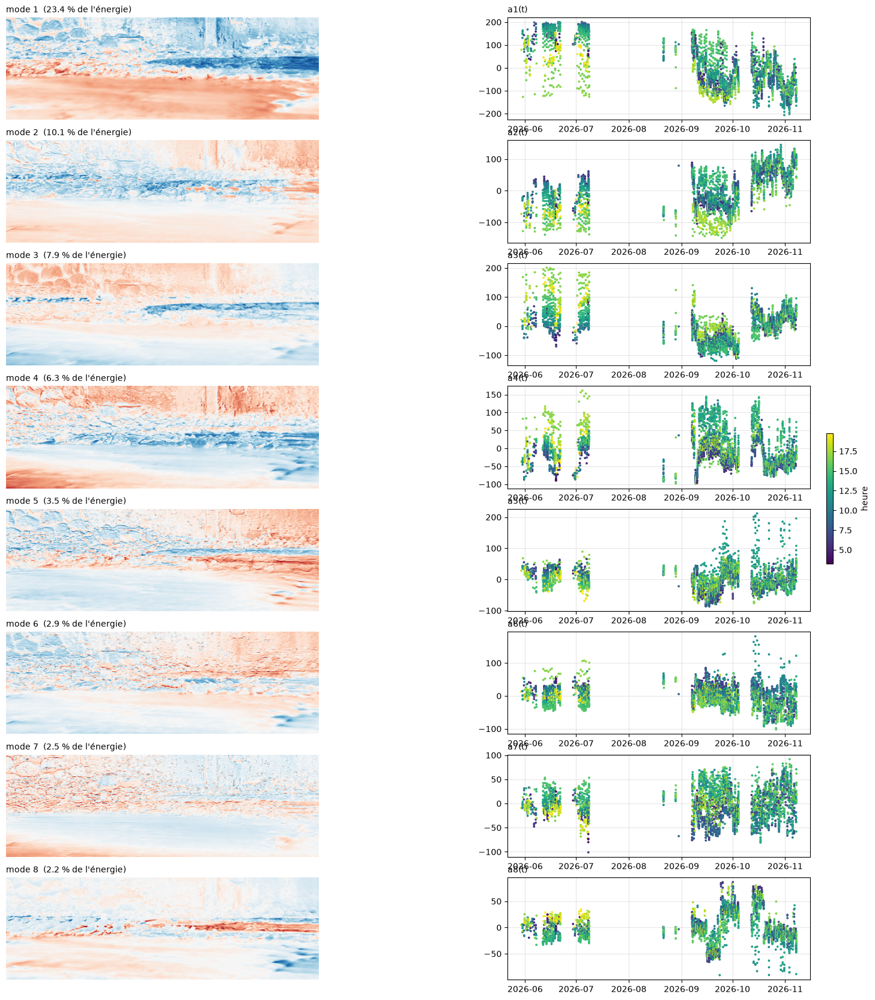

In [9]:
dates = pd.to_datetime(pd.Series(fichiers["train"]).str[:17], format="%Y-%m-%d-%H%M%S")
heures = dates.dt.hour + dates.dt.minute / 60
N_MODES = 8
fig, ax = plt.subplots(N_MODES, 2, figsize=(20, 2.6 * N_MODES), gridspec_kw={"width_ratios": [1.6, 1]})
for k in range(N_MODES):
    m = modes[k].reshape(h, w)
    v = np.abs(m).max()
    ax[k, 0].imshow(m, cmap="RdBu_r", vmin=-v, vmax=v)
    ax[k, 0].set_title(f"mode {k + 1}  ({100 * energie[k]:.1f} % de l'énergie)", loc="left", fontsize=10)
    ax[k, 0].axis("off")
    sc = ax[k, 1].scatter(dates, coefs["train"][:, k], s=3, c=heures, cmap="viridis")
    ax[k, 1].set_title(f"a{k + 1}(t)", loc="left", fontsize=10); ax[k, 1].grid(alpha=.3)
plt.colorbar(sc, ax=ax[:, 1], fraction=0.02, label="heure")
plt.show()

### Les coefficients voient-ils le niveau d'eau ?

Pour les photos train **annotées**, chaque coefficient en fonction de la hauteur d'eau (`niveau_px - decalage_y` ; petit = eau haute). Si un coefficient varie régulièrement avec la hauteur, le réseau aura une prise facile. $r$ : coefficient de corrélation.

3493 photos train annotées


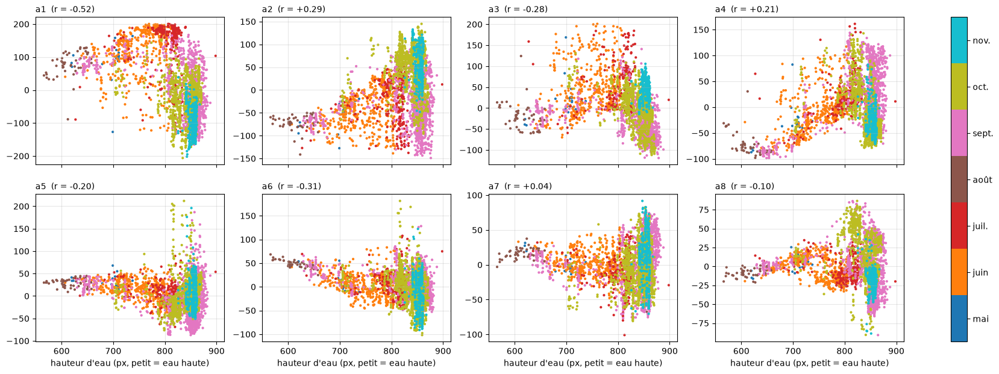

In [10]:
h_eau = (annot["niveau_px"] - annot["decalage_y"]).reindex(fichiers["train"])
ok = h_eau.notna().to_numpy()
mois = dates[ok].dt.month
MOIS = {5: "mai", 6: "juin", 7: "juil.", 8: "août", 9: "sept.", 10: "oct.", 11: "nov."}
cmap_mois = plt.get_cmap("tab10", len(MOIS))
fig, axes = plt.subplots(2, 4, figsize=(20, 7), sharex=True)
for k, ax in enumerate(axes.ravel()):
    a = coefs["train"][ok, k]
    sc = ax.scatter(h_eau[ok], a, s=4, c=mois, cmap=cmap_mois, vmin=4.5, vmax=11.5)
    ax.set_title(f"a{k + 1}  (r = {np.corrcoef(h_eau[ok], a)[0, 1]:+.2f})", loc="left", fontsize=10)
    ax.grid(alpha=.3)
for ax in axes[1]:
    ax.set_xlabel("hauteur d'eau (px, petit = eau haute)")
cb = plt.colorbar(sc, ax=axes, fraction=0.02, ticks=list(MOIS))
cb.ax.set_yticklabels(MOIS.values())
print(f"{ok.sum()} photos train annotées")
plt.show()

### Reconstruction avec K modes

Erreur = $\|x - x_K\| / \|x - \bar{x}\|$ : part des fluctuations qui n'est pas reconstruite. Une photo train et une photo test.

erreur médiane de reconstruction avec 50 modes : {'train': '47 %', 'test': '49 %'}


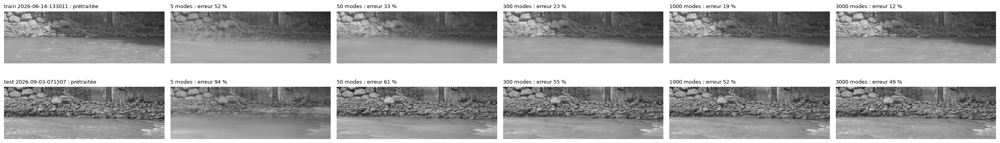

In [11]:
KS = [5, 50, 300, 1000, 3000]
choix = [("train", fichiers["train"].index(annot.index.intersection(fichiers["train"])[100])),
         ("test", fichiers["test"].index(annot.index.intersection(fichiers["test"])[100]))]
fig, axes = plt.subplots(len(choix), len(KS) + 1, figsize=(4.2 * (len(KS) + 1), 2.2 * len(choix)))
for ligne, (s, i) in zip(axes, choix):
    x, a = X[s][i], coefs[s][i]
    ligne[0].imshow(x.reshape(h, w), cmap="gray", vmin=-3, vmax=3)
    ligne[0].set_title(f"{s} {fichiers[s][i][:-4]} : prétraitée", fontsize=9, loc="left")
    for ax, K in zip(ligne[1:], KS):
        rec = xbar + a[:K] @ modes[:K]
        err = np.linalg.norm(x - rec) / np.linalg.norm(x - xbar)
        ax.imshow(rec.reshape(h, w), cmap="gray", vmin=-3, vmax=3)
        ax.set_title(f"{K} modes : erreur {100 * err:.0f} %", fontsize=9, loc="left")
    for ax in ligne:
        ax.axis("off")
plt.tight_layout()

erreur = {s: np.linalg.norm(X[s] - xbar - coefs[s][:, :50] @ modes[:50], axis=1) / np.linalg.norm(X[s] - xbar, axis=1)
          for s in X}
print("erreur médiane de reconstruction avec 50 modes :", {s: f"{100 * np.median(e):.0f} %" for s, e in erreur.items()})

### Sauvegarde pour le réseau

Les coefficients (train et test), les modes et l'image moyenne sont enregistrés dans `data/pod_bande.npz` (le dossier `data/` n'est pas versionné). Le réseau prendra en entrée les premiers coefficients $a_1, \dots, a_K$ de chaque photo.

In [12]:
np.savez_compressed(ROOT / "data" / "pod_bande.npz",
                    modes=modes[:500], xbar=xbar,   # 500 premiers modes seulement (fichier plus léger) energie=energie, taille=np.array([h, w]),
                    coefs_train=coefs["train"], coefs_test=coefs["test"],
                    fichiers_train=np.array(fichiers["train"]), fichiers_test=np.array(fichiers["test"]),
                    Y0=Y0, Y1=Y1, MARGE=MARGE, ECHELLE=ECHELLE)
print("enregistré :", ROOT / "data" / "pod_bande.npz")

enregistré : /Users/mathis/ponts/projet/vision_romanche_level/data/pod_bande.npz


## 5. Réseau : hauteur d'eau à partir des K premiers coefficients POD

- **Entrée** : les K premiers coefficients POD de la photo, $a_1, \dots, a_K$ (centrés réduits avec les moyennes / écarts types du train).
- **Sortie** : la hauteur d'eau `niveau_px - decalage_y` (px).
- **Réseau** : perceptron multicouche (`sklearn.neural_network.MLPRegressor`), 2 couches cachées de 64 et 32 neurones (ReLU), arrêt anticipé sur 10 % du train mis de côté. Pour chaque K, on entraîne avec 3 graines différentes et on moyenne les erreurs.
- **Référence** : une régression linéaire (ridge) sur les mêmes coefficients, pour voir ce que le réseau apporte en plus.
- **Données** : photos annotées uniquement. Entraînement sur les annotées du train, évaluation sur les annotées du test (semaines jamais vues, ni par la POD ni par le réseau).

On fait varier K de 1 jusqu'à tous les modes (un par photo train, environ 3 360).

In [13]:
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

hauteur = (annot["niveau_px"] - annot["decalage_y"])
jeux = {}
for s in ("train", "test"):
    y = hauteur.reindex(fichiers[s]).to_numpy()
    garde = np.isfinite(y)
    jeux[s] = (coefs[s][garde], y[garde], np.array(fichiers[s])[garde])
print({s: len(j[1]) for s, j in jeux.items()}, "photos annotées")

KS = [1, 2, 3, 5, 10, 20, 50, 100, 200, 300, 500, 750, 1000, 1500, 2000, 3000, K_MAX]
GRAINES = [0, 1, 2]
resultats, predictions, predictions_lin = [], {}, {}
for K in KS:
    sx = StandardScaler().fit(jeux["train"][0][:, :K])
    Xtr, Xte = sx.transform(jeux["train"][0][:, :K]), sx.transform(jeux["test"][0][:, :K])
    ytr, yte = jeux["train"][1], jeux["test"][1]
    my, sy = ytr.mean(), ytr.std()

    lin = Ridge(alpha=1.0).fit(Xtr, (ytr - my) / sy)
    p_lin = lin.predict(Xte) * sy + my

    p_tr, p_te = [], []
    for g in GRAINES:
        mlp = MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, learning_rate_init=1e-3, max_iter=3000,
                           early_stopping=True, validation_fraction=0.1, n_iter_no_change=50, random_state=g)
        mlp.fit(Xtr, (ytr - my) / sy)
        p_tr.append(mlp.predict(Xtr) * sy + my)
        p_te.append(mlp.predict(Xte) * sy + my)
    e_tr = [np.abs(p - ytr).mean() for p in p_tr]
    e_te = [np.abs(p - yte).mean() for p in p_te]
    predictions[K] = np.mean(p_te, axis=0)
    predictions_lin[K] = p_lin
    resultats.append({"K": K, "réseau : erreur train (px)": np.mean(e_tr), "réseau : erreur test (px)": np.mean(e_te),
                      "écart entre graines (px)": np.std(e_te),
                      "réseau : test à 10 px près (%)": 100 * np.mean([np.mean(np.abs(p - yte) <= 10) for p in p_te]),
                      "linéaire : erreur test (px)": np.abs(p_lin - yte).mean()})
resultats = pd.DataFrame(resultats).set_index("K").round(1)
resultats

{'train': 3493, 'test': 883} photos annotées


,réseau : erreur train (px),réseau : erreur test (px),écart entre graines (px),réseau : test à 10 px près (%),linéaire : erreur test (px)
K,,,,,
1,29.2,53.9,0.6,10.5,46.9
2,19.5,27.4,0.4,25.1,41.6
3,13.4,31.4,0.4,24.3,38.1
5,9.0,25.4,0.5,24.4,31.6
10,5.2,17.8,0.2,35.2,23.0
20,4.1,14.3,0.9,43.6,21.9
50,3.1,13.5,0.4,46.7,17.1
100,2.0,14.7,0.9,42.1,14.7
200,2.0,13.7,2.0,45.2,15.1


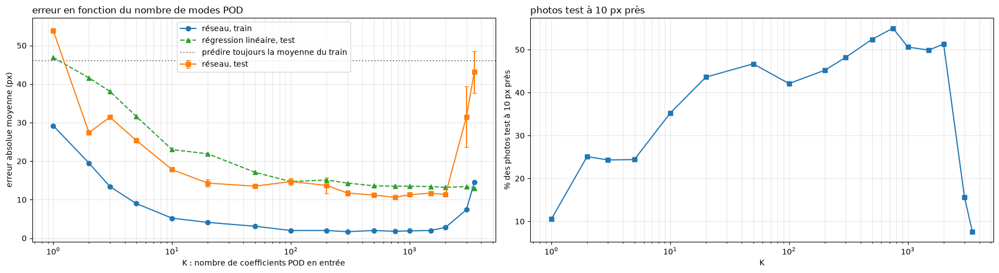

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
ax[0].plot(resultats.index, resultats["réseau : erreur train (px)"], "o-", label="réseau, train")
ax[0].errorbar(resultats.index, resultats["réseau : erreur test (px)"], yerr=resultats["écart entre graines (px)"],
               fmt="s-", capsize=3, label="réseau, test")
ax[0].plot(resultats.index, resultats["linéaire : erreur test (px)"], "^--", label="régression linéaire, test")
ax[0].axhline(np.abs(jeux["test"][1] - jeux["train"][1].mean()).mean(), color="gray", ls=":",
              label="prédire toujours la moyenne du train")
ax[0].set_xscale("log"); ax[0].set_xlabel("K : nombre de coefficients POD en entrée")
ax[0].set_ylabel("erreur absolue moyenne (px)"); ax[0].grid(alpha=.3, which="both"); ax[0].legend()
ax[0].set_title("erreur en fonction du nombre de modes POD", loc="left")

ax[1].plot(resultats.index, resultats["réseau : test à 10 px près (%)"], "s-")
ax[1].set_xscale("log"); ax[1].set_xlabel("K"); ax[1].set_ylabel("% des photos test à 10 px près")
ax[1].grid(alpha=.3, which="both"); ax[1].set_title("photos test à 10 px près", loc="left")
plt.tight_layout()

### Distribution des erreurs sur les photos test

Le tableau ne donne que des moyennes. Ici, pour chaque K, toute la distribution de l'erreur (hauteur prédite - vraie hauteur, en px) sur les 552 photos test annotées : boîte = de 25 % à 75 % des photos, trait = médiane, moustaches = de 5 % à 95 %. Une boîte décalée de 0 veut dire que le modèle se trompe toujours dans le même sens (biais).

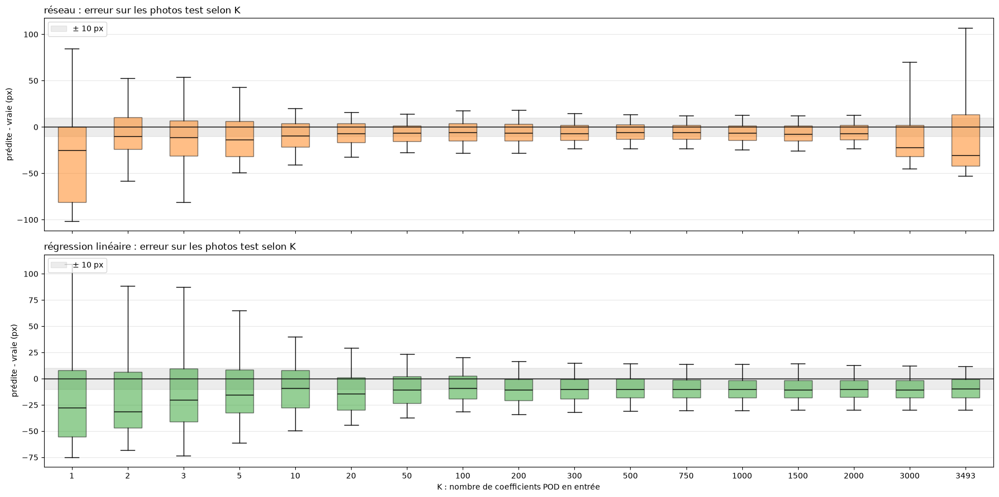

In [15]:
yte = jeux["test"][1]
fig, axes = plt.subplots(2, 1, figsize=(18, 9), sharex=True)
for ax, (nom, preds, couleur) in zip(axes, [("réseau", predictions, "tab:orange"), ("régression linéaire", predictions_lin, "tab:green")]):
    erreurs = [preds[K] - yte for K in KS]
    ax.boxplot(erreurs, whis=(5, 95), showfliers=False, patch_artist=True,
               boxprops=dict(facecolor=couleur, alpha=.5), medianprops=dict(color="k"))
    ax.axhline(0, color="k", lw=1); ax.axhspan(-10, 10, color="gray", alpha=.15, label="± 10 px")
    ax.set_ylabel("prédite - vraie (px)"); ax.grid(alpha=.3, axis="y"); ax.legend(loc="upper left")
    ax.set_title(f"{nom} : erreur sur les photos test selon K", loc="left")
axes[1].set_xticks(range(1, len(KS) + 1), KS)
axes[1].set_xlabel("K : nombre de coefficients POD en entrée")
plt.tight_layout()

|erreur| (px) que 50 / 75 / 90 % des photos test ne dépassent pas :


réseau             linéaire            
       50 %  75 %  90 %     50 %  75 %  90 %
K                                           
1      45.8  86.2  99.4     47.2  64.3  82.7
2      21.3  35.2  56.0     39.0  54.0  78.0
3      22.6  41.5  65.7     32.4  50.9  79.9
5      21.2  35.2  48.5     26.6  41.0  64.5
10     13.7  23.5  35.5     19.9  34.5  45.2
20     10.7  18.1  27.4     20.1  32.3  41.2
50     10.1  17.4  24.9     14.8  25.8  33.4
100    10.5  17.6  24.9     12.7  21.4  29.0
200    10.2  17.4  25.0     13.2  21.5  29.5
300    10.1  15.4  20.8     12.4  20.6  27.8
500     9.3  14.4  20.3     11.8  19.1  25.9
750     8.9  14.0  19.3     11.8  18.8  25.4
1000    9.7  15.2  20.7     11.8  18.7  25.5
1500   10.0  15.4  21.0     12.3  18.5  25.2
2000    9.4  14.9  20.4     12.1  18.3  25.0
3000   27.8  38.4  55.8     12.3  18.9  25.6
3493   37.9  48.3  81.4     11.5  18.4  26.3

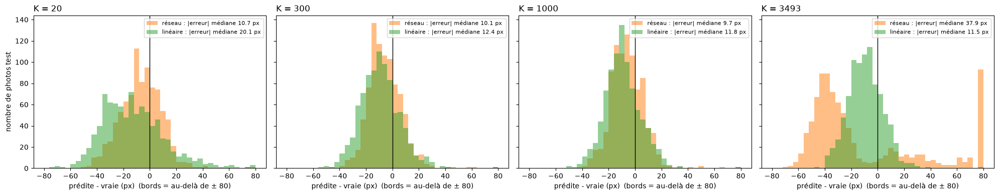

In [16]:
K_montres = [20, 300, 1000, K_MAX]
fig, axes = plt.subplots(1, len(K_montres), figsize=(20, 4), sharey=True)
bins = np.arange(-80, 81, 4)
for ax, K in zip(axes, K_montres):
    for nom, preds, couleur in [("réseau", predictions, "tab:orange"), ("linéaire", predictions_lin, "tab:green")]:
        e = preds[K] - yte
        ax.hist(np.clip(e, bins[0], bins[-1]), bins=bins, alpha=.5, color=couleur,
                label=f"{nom} : |erreur| médiane {np.median(np.abs(e)):.1f} px")
    ax.axvline(0, color="k", lw=1); ax.set_title(f"K = {K}", loc="left"); ax.legend(fontsize=8)
    ax.set_xlabel("prédite - vraie (px)  (bords = au-delà de ± 80)")
axes[0].set_ylabel("nombre de photos test")
plt.tight_layout()

# erreur absolue : quantiles
q = pd.DataFrame({(nom, f"{int(100 * p)} %"): [np.quantile(np.abs(preds[K] - yte), p) for K in KS]
                  for nom, preds in [("réseau", predictions), ("linéaire", predictions_lin)] for p in (0.5, 0.75, 0.9)},
                 index=pd.Index(KS, name="K")).round(1)
print("|erreur| (px) que 50 / 75 / 90 % des photos test ne dépassent pas :")
q

### Le meilleur K en détail

Prédiction contre vraie hauteur sur les photos test, et erreur au cours de la saison (couleur = heure de la photo).

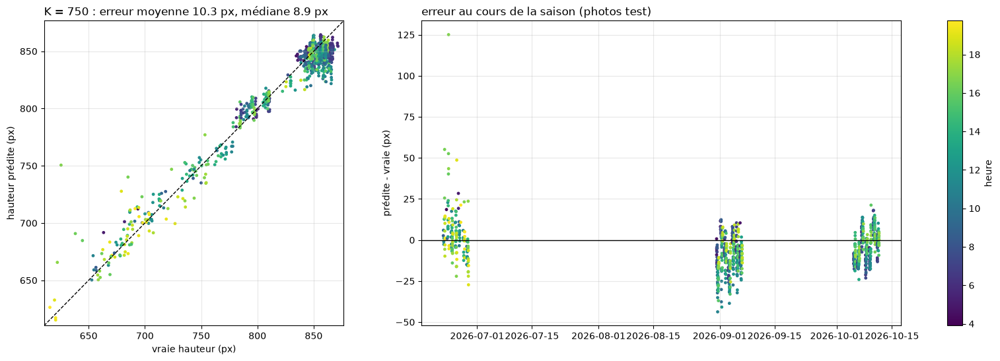

In [17]:
K_best = int(resultats["réseau : erreur test (px)"].idxmin())
yte, noms_te = jeux["test"][1], jeux["test"][2]
pred = predictions[K_best]
dates_te = pd.to_datetime(pd.Series(noms_te).str[:17], format="%Y-%m-%d-%H%M%S")
heures_te = dates_te.dt.hour + dates_te.dt.minute / 60

fig, ax = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [1, 1.6]})
sc = ax[0].scatter(yte, pred, s=6, c=heures_te, cmap="viridis")
lim = [min(yte.min(), pred.min()) - 5, max(yte.max(), pred.max()) + 5]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("vraie hauteur (px)"); ax[0].set_ylabel("hauteur prédite (px)"); ax[0].grid(alpha=.3)
ax[0].set_title(f"K = {K_best} : erreur moyenne {np.abs(pred - yte).mean():.1f} px, "
                f"médiane {np.median(np.abs(pred - yte)):.1f} px", loc="left")
ax[1].scatter(dates_te, pred - yte, s=6, c=heures_te, cmap="viridis")
ax[1].axhline(0, color="k", lw=1); ax[1].grid(alpha=.3)
ax[1].set_ylabel("prédite - vraie (px)"); ax[1].set_title("erreur au cours de la saison (photos test)", loc="left")
plt.colorbar(sc, ax=ax, fraction=0.02, label="heure")
plt.show()

### À quoi ressemble une erreur de 4, 16, 32 ou 64 px ?

Pour se rendre compte de ce qu'on tolère : des photos test dont l'erreur du réseau (meilleur K) vaut environ 4, 16, 32 et 64 px. Pour chaque erreur, une photo où le réseau prédit l'eau trop basse et une où il la prédit trop haute, si elles existent. La bande affichée est la bande découpée et recalée, en couleur et en pleine résolution. **Vert** : niveau annoté ; **rouge** : niveau prédit.

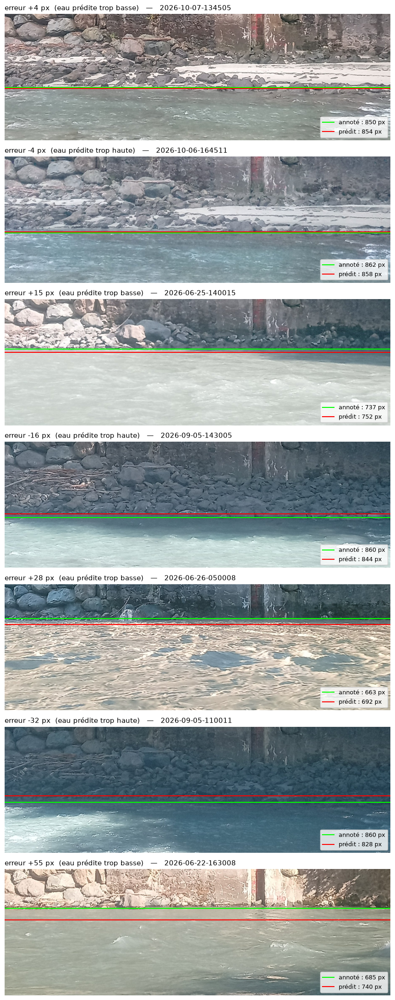

In [18]:
erreur_best = pred - yte                     # prédite - vraie, réseau avec K_best
CIBLES = [4, 16, 32, 64]
choisis = []
for c in CIBLES:
    for signe in (+1, -1):
        i = int(np.argmin(np.abs(erreur_best - signe * c)))
        if abs(abs(erreur_best[i]) - c) <= max(2, 0.15 * c) and i not in [j for j, _ in choisis]:
            choisis.append((i, c))

fig, axes = plt.subplots(len(choisis), 1, figsize=(18, 3.1 * len(choisis)))
for ax, (i, c) in zip(np.atleast_1d(axes), choisis):
    nom = noms_te[i]
    dx, dy = cat.at[nom, "decalage_x"], cat.at[nom, "decalage_y"]
    ax.imshow(decouper(Image.open(IMAGES / nom), dx, dy))
    # dans la bande recalée, une hauteur h (corrigée du décalage) est à la ligne h - Y0
    ax.axhline(yte[i] - Y0, color="lime", lw=1.5, label=f"annoté : {yte[i]:.0f} px")
    ax.axhline(pred[i] - Y0, color="red", lw=1.5, label=f"prédit : {pred[i]:.0f} px")
    sens = "eau prédite trop basse" if erreur_best[i] > 0 else "eau prédite trop haute"
    ax.set_title(f"erreur {erreur_best[i]:+.0f} px  ({sens})   —   {nom[:-4]}", loc="left", fontsize=11)
    ax.legend(loc="lower right", fontsize=9); ax.axis("off")
plt.tight_layout()